# Связаны ли брокерские депозиты с банкротствами банков?

Пример итогового проекта по курсу «Введение в анализ данных».

Сначала сравним две группы банков, затем проверим, помогает ли признак брокерских депозитов модели различать будущих банкротов и остальные банки. Все расчёты относятся к учебной выборке и кризису 2008–2012 годов.

## 1. Вопрос и заказчик

**Вопрос:** чаще ли банкротились банки с высокой долей брокерских депозитов и добавляет ли этот признак информацию к четырём показателям баланса?

**Кому нужен ответ:** банковскому аналитику, который выбирает показатели для проверки риска.

Брокерские депозиты — депозиты, привлечённые через посредников. Мы изучаем связь с банкротствами. По этому анализу нельзя определить, что произойдёт, если ограничить такие депозиты.

## 2. Откуда данные

Источник — подготовленная для курса квартальная отчётность банков США (FDIC). Файл `banks_panel.parquet` содержит показатели банков, `failures.parquet` — даты и типы событий.

В исходной панели **одна строка — банк за один квартал**. Для исследования возьмём отчёт на 31.12.2006: тогда **одна строка будет соответствовать одному банку**. Исход — банкротство в 2008–2012 годах.

**Особенность выборки:** по описанию курса, в неё включены все банкроты и 2 000 случайно выбранных выживших банков. Поэтому доли банкротств здесь выше, чем среди всех банков США. Их нельзя читать как вероятность банкротства банка в реальной банковской системе.

Подключим библиотеки. `pandas` нужен для таблиц, `matplotlib` — для графиков, `sklearn` — для логистической регрессии. `SEED` фиксирует случайность, чтобы при повторном запуске получалось то же разбиение данных.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, RocCurveDisplay

DATA = "https://raw.githubusercontent.com/nvvoitov/da_intro/main/data/"
SEED = 20260101
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 12

Загрузим оба файла и проверим их размер. В списке событий есть не только банкротства (`FAILURE`), но и помощь банкам (`ASSISTANCE`); дальше мы будем считать только банкротства.

In [2]:
panel = pd.read_parquet(DATA + "banks_panel.parquet")
failures = pd.read_parquet(DATA + "failures.parquet")

print("Панель: строк, колонок =", panel.shape)
print("Банков в панели:", panel["cert"].nunique())
print("Период:", panel["repdte"].min().date(), "—", panel["repdte"].max().date())
print("Список событий: строк, колонок =", failures.shape)
print("Типы событий:")
print(failures["restype"].value_counts())

Панель: строк, колонок = (152152, 42)
Банков в панели: 2586
Период: 2001-03-31 — 2026-06-30
Список событий: строк, колонок = (594, 6)
Типы событий:
restype
FAILURE       581
ASSISTANCE     13
Name: count, dtype: int64


В исходной панели 152 152 строки, 42 колонки и 2 586 банков. Она охватывает период с 31.03.2001 по 30.06.2026. В отдельном файле событий — 594 записи: 581 банкротство и 13 случаев помощи.

Посмотрим на первые строки. `cert` — идентификатор банка, `repdte` — дата отчёта. Денежные суммы, включая `assets`, записаны в тысячах долларов.

In [3]:
panel[["cert", "name", "repdte", "assets", "l_brokered_share",
       "c_equity_assets", "a_npl_gross_loans",
       "a_cre_concentration", "l_liquid_assets_ratio"]].head()

,cert,name,repdte,assets,l_brokered_share,c_equity_assets,a_npl_gross_loans,a_cre_concentration,l_liquid_assets_ratio
0,41,Phenix-Girard Bank,2001-03-31,106506.0,0.0,0.133138,0.001333,0.533477,0.442726
1,41,Phenix-Girard Bank,2001-06-30,107577.0,0.0,0.135308,0.001288,0.477399,0.448646
2,41,Phenix-Girard Bank,2001-09-30,104196.0,0.0,0.147597,0.004795,0.504449,0.420410
3,41,Phenix-Girard Bank,2001-12-31,106383.0,0.0,0.138706,0.003148,0.547738,0.367408
4,41,Phenix-Girard Bank,2002-03-31,104151.0,0.0,0.143119,0.002784,0.580042,0.364490


## 3. Какие переменные используем

Четыре показателя описывают капитал, качество кредитов, структуру кредитования и ликвидность банка. В файле показатели записаны в долях единицы: например, 0,05 означает 5 %. В таблицах и на графиках ниже переведём их в проценты.

| Переменная | Что означает |
|---|---|
| `c_equity_assets` | Капитал / активы: доля собственных средств банка |
| `a_npl_gross_loans` | Просроченные кредиты / все кредиты |
| `a_cre_concentration` | Кредиты под коммерческую недвижимость / все кредиты |
| `l_liquid_assets_ratio` | Ликвидные активы / активы |
| `l_brokered_share` | Брокерские депозиты / все депозиты |
| `brokered` | 1, если доля брокерских депозитов выше 5 %; иначе 0 |
| `failed` | 1, если банк обанкротился в 2008–2012 годах; иначе 0 |

Порог 5 % нужен для простого сравнения двух групп. Группа «≤ 5 %» тоже может иметь брокерские депозиты.

Запишем названия четырёх показателей в список, чтобы не повторять их в каждой ячейке.

In [4]:
FEATURES = ["c_equity_assets", "a_npl_gross_loans",
            "a_cre_concentration", "l_liquid_assets_ratio"]
NAMES = {"c_equity_assets": "Капитал / активы",
         "a_npl_gross_loans": "Просрочка / кредиты",
         "a_cre_concentration": "Недвижимость / кредиты",
         "l_liquid_assets_ratio": "Ликвидные активы / активы"}

## 4. Как получили выборку

Оставим отчёты на 31.12.2006 и банки с активами больше 50 млн долларов. В исходной таблице суммы даны в тысячах долларов, поэтому сравниваем `assets` с 50 000.

In [5]:
banks = panel[panel["repdte"] == "2006-12-31"].copy()
print("Отчётов на 31.12.2006:", len(banks))
selection_counts = [len(banks)]

before = len(banks)
banks = banks[banks["assets"] > 50_000].copy()
selection_counts.append(len(banks))
print("После фильтра по размеру:", len(banks))
print("Исключено по размеру:", before - len(banks))

Отчётов на 31.12.2006: 2114
После фильтра по размеру: 1699
Исключено по размеру: 415


Проверим пропуски только в нужных для исследования показателях. Удалим банки с пропусками; складывать числа пропусков по колонкам нельзя, потому что у одного банка их может быть несколько.

In [6]:
print("Пропуски после фильтра по размеру:")
print(banks[FEATURES + ["l_brokered_share"]].isna().sum())

before = len(banks)
banks = banks.dropna(subset=FEATURES + ["l_brokered_share"]).copy()
selection_counts.append(len(banks))
print("После удаления банков с пропусками:", len(banks))
print("Исключено из-за пропусков:", before - len(banks))

Пропуски после фильтра по размеру:
c_equity_assets          0
a_npl_gross_loans        6
a_cre_concentration      6
l_liquid_assets_ratio    0
l_brokered_share         4
dtype: int64
После удаления банков с пропусками: 1693
Исключено из-за пропусков: 6


Не будем включать банки, которые обанкротились до начала периода наблюдения за исходом. Здесь и далее банкротством считаем только событие `FAILURE`.

Это ретроспективный анализ банков, доживших до начала 2008 года. Исключение использует информацию, которая ещё не была известна на 31.12.2006, поэтому такой отбор не подходит для готового прогноза на ту дату.

In [7]:
early_failures = failures[(failures["restype"] == "FAILURE")
                          & (failures["fail_date"] < "2008-01-01")]
before = len(banks)
banks = banks[~banks["cert"].isin(early_failures["cert"])].copy()
selection_counts.append(len(banks))
print("После исключения ранних банкротств:", len(banks))
print("Исключено ранних банкротств:", before - len(banks))
print("Уникальных банков:", banks["cert"].nunique())

После исключения ранних банкротств: 1691
Исключено ранних банкротств: 2
Уникальных банков: 1691


Посмотрим, сколько банков остаётся после каждого фильтра. Длина столбика показывает число банков; подписи помогают увидеть небольшие изменения после удаления пропусков и ранних банкротств. Значения берём из расчётов выше.

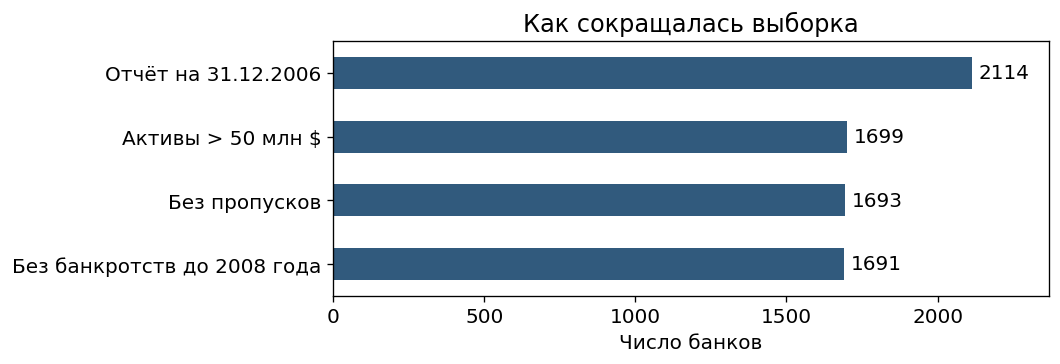

In [8]:
selection = pd.Series(selection_counts, index=[
    "Отчёт на 31.12.2006", "Активы > 50 млн $",
    "Без пропусков", "Без банкротств до 2008 года"])
ax = selection.plot.barh(figsize=(9, 3.2), color="#315a7d")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, selection.max() * 1.12)
ax.set_xlabel("Число банков")
ax.set_title("Как сокращалась выборка")
plt.tight_layout()
plt.show()

Добавим два признака с ответами «да / нет»: банкротство в 2008–2012 годах и доля брокерских депозитов выше 5 %. Для модели запишем их как 1 и 0. Ноль в `failed` означает отсутствие банкротства в указанном периоде, а не отсутствие проблем у банка вообще.

In [9]:
crisis_failures = failures[(failures["restype"] == "FAILURE")
                           & failures["fail_date"].between("2008-01-01", "2012-12-31")]
banks["failed"] = banks["cert"].isin(crisis_failures["cert"]).astype(int)
banks["brokered"] = (banks["l_brokered_share"] > 0.05).astype(int)
banks = banks.reset_index(drop=True)

print("Банков в исследовании:", len(banks))
print("Банкротств в 2008–2012 годах:", banks["failed"].sum())
print(f"Доля банкротств: {banks['failed'].mean():.1%}")

Банков в исследовании: 1691
Банкротств в 2008–2012 годах: 411
Доля банкротств: 24.3%


От 2 114 отчётов на выбранную дату осталось **1 691 наблюдение, по одному на банк**. Фильтр по активам исключил 415 банков, пропуски — ещё 6, ранние банкротства — 2. В итоговой выборке 411 банкротств, или 24,3 %.

Теперь посмотрим на распределение четырёх показателей. `.describe()` показывает среднее, разброс, минимум, максимум и квартили. Столбец `50%` — медиана: половина значений ниже неё, половина выше.

In [10]:
description = (banks[FEATURES] * 100).rename(columns=NAMES).describe().T
print("Показатели в процентах; count — число банков")
description.round(2)

Показатели в процентах; count — число банков


,count,mean,std,min,25%,50%,75%,max
Капитал / активы,1691.0,10.71,4.59,-0.15,8.24,9.48,11.67,78.36
Просрочка / кредиты,1691.0,0.91,2.73,0.00,0.11,0.44,1.07,100.00
Недвижимость / кредиты,1691.0,40.36,22.01,0.00,22.86,39.52,57.53,95.83
Ликвидные активы / активы,1691.0,22.90,14.69,0.00,12.23,19.67,30.87,92.43


У некоторых банков показатели сильно отличаются от остальных: например, доля просроченных кредитов достигает 100 %. В этом простом анализе оставляем исходные значения и сравниваем группы по медианам, которые меньше реагируют на отдельные крайние наблюдения. Зависимость результата модели от таких банков остаётся ограничением работы.

Гистограмма показывает распределение доли брокерских депозитов во всей итоговой выборке. Каждый столбик — число банков в интервале шириной 5 процентных пунктов. По горизонтали показана полная шкала от 0 до 100 %, без удаления редких больших значений. Пунктирная линия отмечает порог 5 %, который делит банки на две группы.

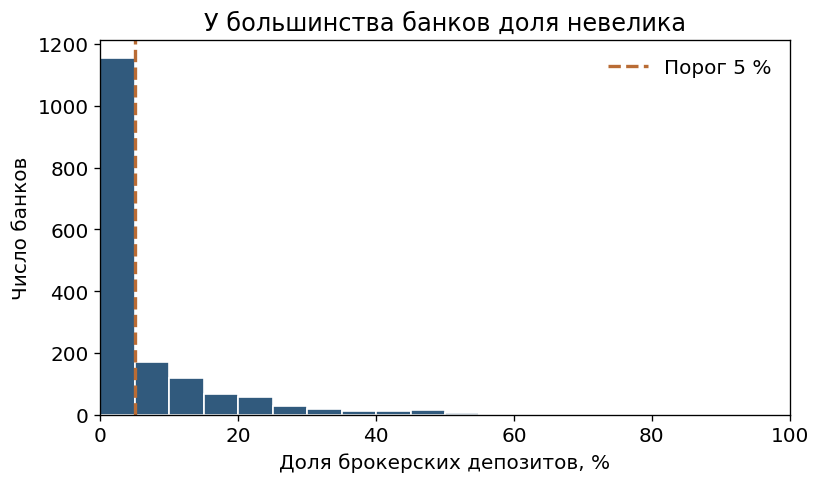

In [11]:
plt.figure(figsize=(7, 4.2))
plt.hist(banks["l_brokered_share"] * 100, bins=np.arange(0, 105, 5),
         color="#315a7d", edgecolor="white")
plt.axvline(5, color="#b96c35", linestyle="--", linewidth=2, label="Порог 5 %")
plt.xlim(0, 100)
plt.xlabel("Доля брокерских депозитов, %")
plt.ylabel("Число банков")
plt.title("У большинства банков доля невелика")
plt.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

## 5. План проверки

1. Сравним число и долю банкротств в группах «≤ 5 %» и «> 5 %» брокерских депозитов.
2. Посмотрим, различаются ли их капитал, кредиты и ликвидность.
3. Возьмём одну логистическую регрессию с двумя наборами признаков: четыре показателя баланса; те же показатели плюс `brokered`.
4. Обучим обе версии на 70 % банков и проверим на одних и тех же оставшихся 30 %. Настройки модели и порог 5 % в этом примере фиксированы, подбор по тесту не проводится.
5. Сравним ROC AUC и с помощью бутстрапа проверим, насколько устойчиво различие на тестовых банках.

Делим по банкам: каждый банк встречается только один раз. Показатели известны на конец 2006 года, исход относится к 2008–2012 годам. При этом выборка ограничена банками, не обанкротившимися до 2008 года: это ретроспективный анализ. Это проверка на других банках того же исторического периода; она не показывает качество прогноза на новый кризис.

## 6. Простое сравнение групп

Посчитаем банки, банкротства и долю банкротств в каждой группе. Разница между долями измеряется в **процентных пунктах**, а не в процентах.

In [12]:
groups = banks.groupby("brokered")["failed"].agg(["count", "sum", "mean"])
groups.columns = ["Банков", "Банкротств", "Доля банкротств, %"]
groups["Доля банкротств, %"] = groups["Доля банкротств, %"] * 100
groups.index = ["Брокерские депозиты ≤ 5 %", "Брокерские депозиты > 5 %"]

raw_difference = groups.iloc[1, 2] - groups.iloc[0, 2]
print(f"Разница долей банкротств: {raw_difference:.1f} п.п.")
groups.round(1)

Разница долей банкротств: 31.2 п.п.


,Банков,Банкротств,"Доля банкротств, %"
Брокерские депозиты ≤ 5 %,1154,166,14.4
Брокерские депозиты > 5 %,537,245,45.6


Покажем доли на простом графике. Полная таблица выше нужна, чтобы за процентами были видны размеры групп.

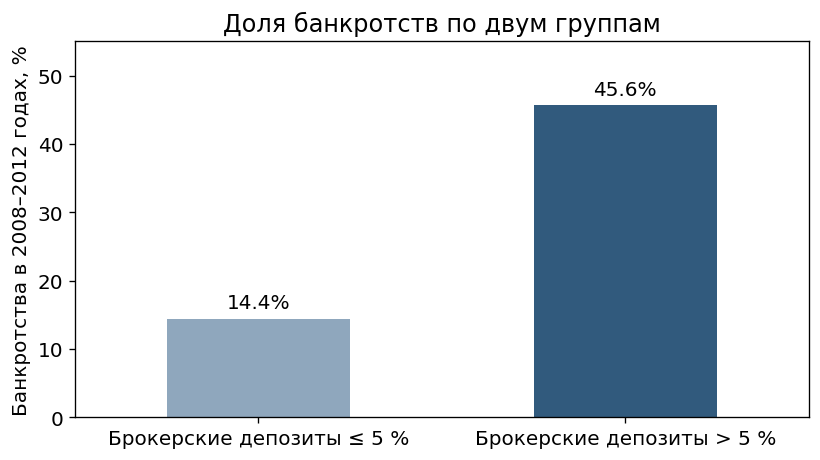

In [13]:
ax = groups["Доля банкротств, %"].plot.bar(
    figsize=(7, 4), color=["#8fa7bd", "#315a7d"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)
plt.ylabel("Банкротства в 2008–2012 годах, %")
plt.xlabel("")
plt.ylim(0, 55)
plt.title("Доля банкротств по двум группам")
plt.tight_layout()
plt.show()

В группе «> 5 %» обанкротились 245 из 537 банков (**45,6 %**), в группе «≤ 5 %» — 166 из 1 154 (**14,4 %**). Разница — **31,2 п.п.**

Это заметная связь в учебной выборке. Она пока ничего не говорит о причинах: группы могут различаться и по другим характеристикам.

## 7. Чем ещё различаются группы

Сравним медианы четырёх показателей. Все значения в следующей таблице — проценты от соответствующей базы: активов или кредитов.

In [14]:
medians = banks.groupby("brokered")[FEATURES].median().T * 100
medians = medians.rename(index=NAMES)
medians.columns = ["Брокерские ≤ 5 %", "Брокерские > 5 %"]
print("Медианы показателей, %")
medians.astype(float).round(2)

Медианы показателей, %


,Брокерские ≤ 5 %,Брокерские > 5 %
Капитал / активы,9.61,9.26
Просрочка / кредиты,0.41,0.54
Недвижимость / кредиты,34.97,51.86
Ликвидные активы / активы,23.29,14.17


Покажем ту же таблицу на графике. Каждая пара столбиков — **медианы двух групп, а не отдельные банки**. Подписи позволяют сравнить и небольшие значения просрочки. Основание процентов зависит от показателя: активы или кредиты.

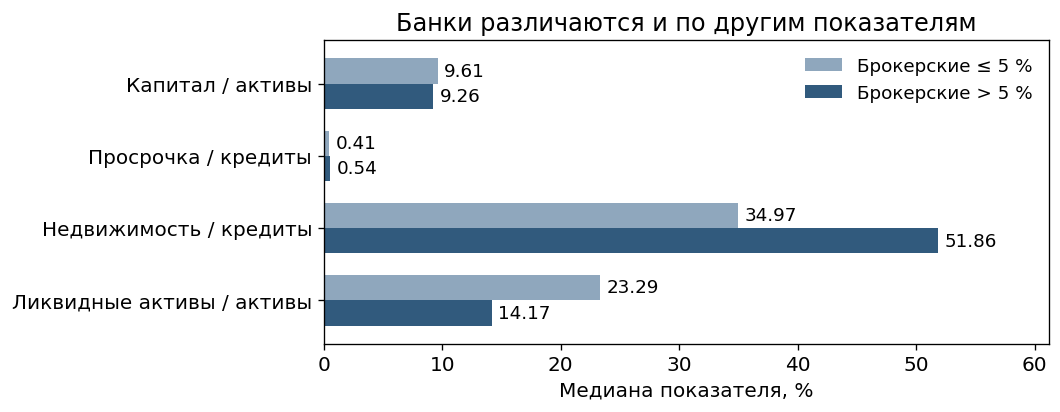

In [15]:
ax = medians.plot.barh(figsize=(9, 3.6), color=["#8fa7bd", "#315a7d"], width=0.7)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=4, fontsize=11)
ax.bar_label(ax.containers[1], fmt="%.2f", padding=4, fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, medians.max().max() * 1.18)
ax.set_xlabel("Медиана показателя, %")
ax.set_title("Банки различаются и по другим показателям")
ax.legend(loc="upper right", frameon=False, fontsize=11)
plt.tight_layout()
plt.show()

Особенно заметны различия в кредитах под недвижимость и ликвидности. В группе «> 5 %» медианная доля кредитов под недвижимость — **51,86 %** против **34,97 %**, а ликвидных активов — **14,17 %** против **23,29 %**.

Поэтому простое сравнение долей банкротств не отделяет брокерские депозиты от других особенностей банков. Проверим, полезен ли этот признак модели, которая уже учитывает четыре показателя.

## 8. Добавляет ли признак информацию модели

Логистическая регрессия связывает показатели банка с вероятностью исхода. Здесь используем её прогнозы для ранжирования банков по риску.

**ROC AUC** показывает, как часто модель ставит случайно выбранного банкрота выше случайно выбранного банка без банкротства. При одинаковом прогнозе для всех AUC равен 0,5; идеальное разделение даёт 1. Это не доля правильно угаданных банкротств.

Сначала разделим банки на обучение и тест. `stratify` сохраняет примерно одинаковую долю банкротств в обеих частях. Проверим размеры и число событий.

In [16]:
train, test = train_test_split(
    banks, test_size=0.30, stratify=banks["failed"], random_state=SEED)

split = pd.DataFrame({
    "Банков": [len(train), len(test)],
    "Банкротств": [train["failed"].sum(), test["failed"].sum()],
    "Доля банкротств, %": [train["failed"].mean() * 100, test["failed"].mean() * 100]},
    index=["Обучение", "Тест"])
split.round(1)

,Банков,Банкротств,"Доля банкротств, %"
Обучение,1183,288,24.3
Тест,508,123,24.2


У обеих версий модели одинаковые настройки. `StandardScaler` приводит показатели к сопоставимому масштабу; `make_pipeline` объединяет эту подготовку с моделью. Средние и разброс для масштабирования считаются только по обучающим банкам.

Сначала обучим модель на четырёх показателях, затем добавим `brokered`. Тестовые банки в обучение не попадают.

In [17]:
model_base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model_brokered = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

model_base.fit(train[FEATURES], train["failed"])
model_brokered.fit(train[FEATURES + ["brokered"]], train["failed"])

p_base = model_base.predict_proba(test[FEATURES])[:, 1]
p_brokered = model_brokered.predict_proba(test[FEATURES + ["brokered"]])[:, 1]
y_test = test["failed"].to_numpy()

Посчитаем AUC на одних и тех же тестовых банках. Для ориентира добавим самый простой прогноз: всем банкам назначается доля банкротств в обучающей выборке. Он никого не различает и даёт AUC 0,5.

In [18]:
p_constant = np.full(len(test), train["failed"].mean())
auc_constant = roc_auc_score(y_test, p_constant)
auc_base = roc_auc_score(y_test, p_base)
auc_brokered = roc_auc_score(y_test, p_brokered)
auc_difference = auc_brokered - auc_base

scores = pd.DataFrame({"ROC AUC на тесте": [auc_constant, auc_base, auc_brokered]},
    index=["Одинаковый прогноз для всех", "Четыре показателя", "Четыре показателя + brokered"])
print(f"Прирост AUC после добавления brokered: {auc_difference:+.3f}")
scores.round(3)

Прирост AUC после добавления brokered: +0.012


,ROC AUC на тесте
Одинаковый прогноз для всех,0.500
Четыре показателя,0.811
Четыре показателя + brokered,0.823


Сравним три значения AUC на общей шкале от 0 до 1. Так видно и преимущество моделей перед одинаковым прогнозом для всех, и небольшой прирост от добавления брокерских депозитов.

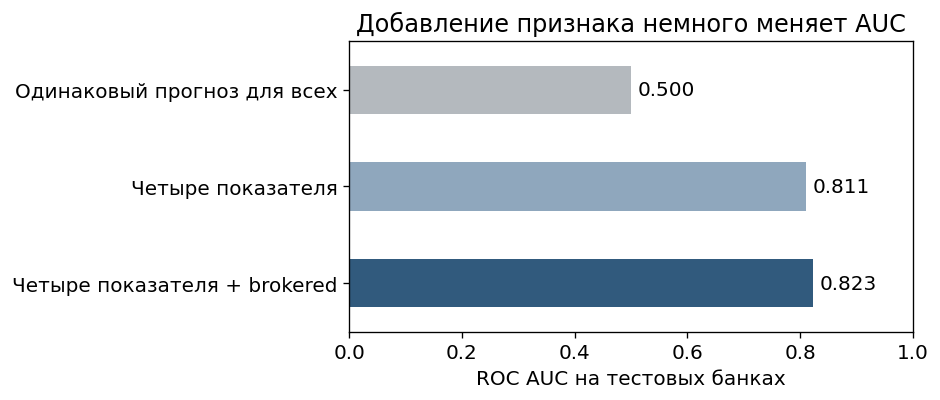

In [19]:
ax = scores["ROC AUC на тесте"].plot.barh(
    figsize=(8, 3.5), color=["#b4b9be", "#8fa7bd", "#315a7d"])
ax.bar_label(ax.containers[0], fmt="%.3f", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("ROC AUC на тестовых банках")
ax.set_title("Добавление признака немного меняет AUC")
plt.tight_layout()
plt.show()

ROC-кривые показывают соотношение найденных банкротств и ложных тревог при разных порогах. Чем ближе кривая к левому верхнему углу, тем лучше; пунктир соответствует одинаковому прогнозу для всех.

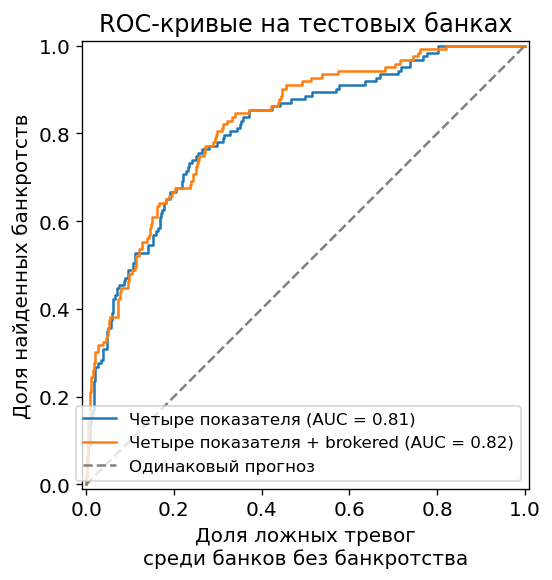

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, p_base, name="Четыре показателя", ax=ax)
RocCurveDisplay.from_predictions(y_test, p_brokered,
                                name="Четыре показателя + brokered", ax=ax)
ax.plot([0, 1], [0, 1], "--", color="grey", label="Одинаковый прогноз")
ax.set_xlabel("Доля ложных тревог\nсреди банков без банкротства")
ax.set_ylabel("Доля найденных банкротств")
ax.set_title("ROC-кривые на тестовых банках")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

В обучение вошли 1 183 банка, в тест — 508. На тесте AUC модели с четырьмя показателями равен **0,811**, с признаком брокерских депозитов — **0,823**. Прирост составляет **0,012**.

Модели заметно лучше одинакового прогноза для всех (AUC 0,500), а различие между ними небольшое. Одной этой разницы недостаточно, чтобы уверенно говорить о пользе нового признака.

## 9. Насколько надёжен прирост AUC

Бутстрап помогает оценить, как изменится результат, если набор тестовых банков окажется немного другим. 500 раз случайно выберем столько же тестовых банков **с возвращением**: один банк может попасть в выборку несколько раз.

В каждой выборке используем одинаковые банки для обеих моделей и считаем разницу AUC. Это парное сравнение. Прогнозы уже получены и остаются фиксированными; модели заново не обучаем.

In [21]:
rng = np.random.default_rng(SEED)
bootstrap_differences = []

for repeat in range(500):
    positions = rng.integers(0, len(test), len(test))
    auc_base_sample = roc_auc_score(y_test[positions], p_base[positions])
    auc_brokered_sample = roc_auc_score(y_test[positions], p_brokered[positions])
    bootstrap_differences.append(auc_brokered_sample - auc_base_sample)

low, high = np.percentile(bootstrap_differences, [2.5, 97.5])
print("Число бутстрап-выборок:", len(bootstrap_differences))
print(f"Прирост AUC: {auc_difference:+.3f}")
print(f"95%-й бутстрап-интервал: [{low:+.3f}; {high:+.3f}]")

Число бутстрап-выборок: 500
Прирост AUC: +0.012
95%-й бутстрап-интервал: [-0.008; +0.034]


На гистограмме — 500 значений прироста AUC из бутстрапа. Высота столбика показывает, сколько повторных выборок дало прирост в этом диапазоне. Закрашенная область — 95%-й бутстрап-интервал; линии отмечают ноль и прирост на исходном тесте.

Это разброс результата при повторном отборе тестовых банков, **а не распределение вероятности истинного эффекта**. Модели и их прогнозы во всех повторах остаются теми же.

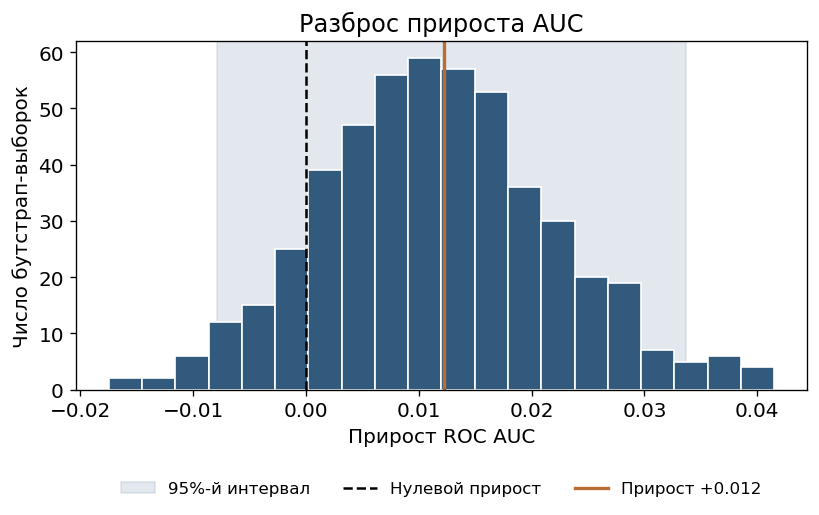

In [22]:
plt.figure(figsize=(7, 4.6))
plt.axvspan(low, high, color="#8fa7bd", alpha=0.25, label="95%-й интервал")
plt.hist(bootstrap_differences, bins=20, color="#315a7d", edgecolor="white")
plt.axvline(0, color="black", linestyle="--", linewidth=1.5, label="Нулевой прирост")
plt.axvline(auc_difference, color="#b96c35", linewidth=2,
            label=f"Прирост {auc_difference:+.3f}")
plt.xlabel("Прирост ROC AUC")
plt.ylabel("Число бутстрап-выборок")
plt.title("Разброс прироста AUC")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22),
           ncol=3, frameon=False, fontsize=10)
plt.tight_layout()
plt.show()

Прирост AUC — **+0,012**, 95%-й бутстрап-интервал — **от −0,008 до +0,034**. Интервал включает ноль: на этих тестовых банках нельзя уверенно утверждать, что добавление брокерских депозитов улучшает ранжирование.

Это не доказательство отсутствия связи. Проверка показывает, что небольшой прирост может зависеть от состава тестовой выборки. Интервал учитывает только эту неопределённость: он не учитывает повторное обучение модели или выбор другого исторического периода.

## 10. Выводы и ограничения

Банки с долей брокерских депозитов выше 5 % банкротились чаще: **45,6 % против 14,4 %** в учебной выборке. Они также больше кредитовали под недвижимость и держали меньше ликвидных активов.

После добавления брокерских депозитов к четырём показателям AUC вырос с **0,811 до 0,823**, но интервал для прироста включает ноль. **Уверенного улучшения ранжирования на этом тесте не получили.**

Для аналитика брокерские депозиты — повод проверить банк подробнее вместе с его кредитным портфелем и ликвидностью. Оснований вводить отдельное правило оценки риска только по этому показателю работа не даёт.

Ограничения:

- Учебная выборка содержит повышенную долю банкротов. Проценты нельзя переносить на все банки США; AUC также измерен только на этой выборке.
- Анализ связи не доказывает, что брокерские депозиты стали причиной банкротств или что их ограничение снизит риск.
- Изучены один исторический период, один порог 5 % и одно разбиение на обучение и тест. Банки, обанкротившиеся до 2008 года, исключены с учётом будущего относительно среза 2006 года. Качество настоящего прогноза на будущее не проверялось.
- Модель использует только четыре показателя баланса; неизвестные факторы и крайние значения могут влиять на результат. Бутстрап не учитывает повторное обучение.